In [1]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LassoCV
from sklearn.metrics import mean_squared_error, r2_score

# Load data
df = pd.read_csv("data/case1/train1.csv")
test_df = pd.read_csv("data/case1/test1.csv")

# Create rpm feature
df["kilo_rpm"] = df["speed_rpm"] / 1000
test_df["kilo_rpm"] = test_df["speed_rpm"] / 1000

# Targets
y_train = df["power_w"]
y_test = test_df["power_w"]

# Generate all polynomial terms up to degree 3
poly = PolynomialFeatures(degree=3, include_bias=False)

X_train = poly.fit_transform(
    df[["kilo_rpm", "flow_m3_h"]]
)

X_test = poly.transform(
    test_df[["kilo_rpm", "flow_m3_h"]]
)

# Names of generated features
feature_names = poly.get_feature_names_out(
    ["kilo_rpm", "flow_m3_h"]
)

# Scale features (important for Lasso)
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Feature selection with Lasso
lasso = LassoCV(
    cv=5,
    max_iter=100000
)

lasso.fit(X_train_scaled, y_train)

# Predictions
predictions = lasso.predict(X_test_scaled)

# Performance
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)

print(f"Chosen alpha: {lasso.alpha_:.6f}")
print(f"Test MSE:  {mse:.3f}")
print(f"Test RMSE: {rmse:.3f} W")
print(f"Test R²:   {r2:.6f}")

# Show selected terms
print("\nSelected polynomial terms:")

for name, coef in zip(feature_names, lasso.coef_):
    if abs(coef) > 1e-6:
        print(f"{name:30} {coef:.6f}")

Chosen alpha: 0.523077
Test MSE:  130.678
Test RMSE: 11.431 W
Test R²:   0.999549

Selected polynomial terms:
kilo_rpm                       0.924449
kilo_rpm flow_m3_h             1.286334
kilo_rpm^3                     256.639594
kilo_rpm^2 flow_m3_h           570.054095
flow_m3_h^3                    -313.829171


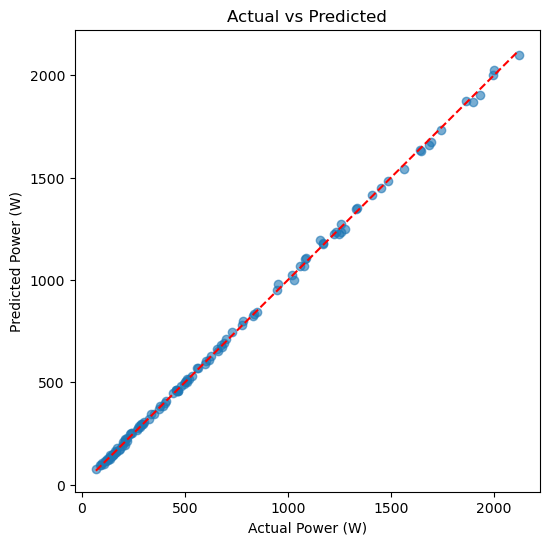

In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.scatter(y_test, predictions, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Power (W)")
plt.ylabel("Predicted Power (W)")
plt.title("Actual vs Predicted")
plt.show()

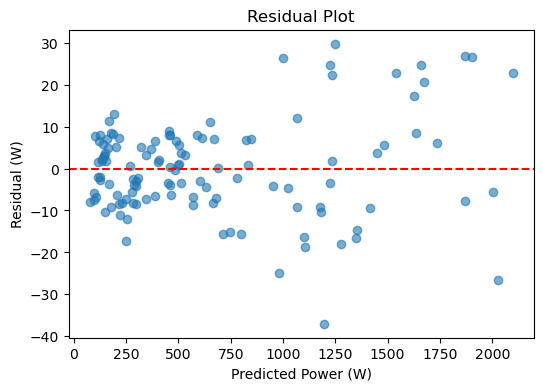

In [3]:
residuals = y_test - predictions

plt.figure(figsize=(6,4))
plt.scatter(predictions, residuals, alpha=0.6)

plt.axhline(0, color='red', linestyle='--')

plt.xlabel("Predicted Power (W)")
plt.ylabel("Residual (W)")
plt.title("Residual Plot")
plt.show()